In [35]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
#SFC mice



#create data - include non-learners
x_sfc = np.array([68.2, 64.1,59.1,65.1,64.3, 65.7, 65.1, 64.7,  65.9, 54.4]) #decoding
y_sfc = np.array(  [10, 30, 17, 22, 20, 25, 50, 28, 11, 2])  #freezing SFC (seconds)


#x_soc = np.array( [55.3,65.5,57.2,62.1,62.6, 59.7, 63.3, 65.1, 58.1, 60.4])
x2_soc = np.array([55.3,57.2, 58.1, 59.7, 62.1, 62.6,   63.3,   60.4, 65.5,65.1]) #decoding soc
y_soc = np.array([0,1,0,0,0,1,0,0,0,0]) #freezing (seconds) soc

x = np.subtract(x_sfc, x_soc)
y = np.subtract(y_sfc, y_soc)
flag = ['n' for i in range(len(x))]

print(x)
print(y)

#print(np.corrcoef(x,y))
print(stats.pearsonr(x, y))
print(stats.spearmanr(x, y))
print(np.mean(y))

[12.9 -1.4  1.9  3.   1.7  6.   1.8 -0.4  7.8 -6. ]
[10 29 17 22 20 24 50 28 11  2]
PearsonRResult(statistic=-0.10363717774866482, pvalue=0.7757129984599697)
SpearmanrResult(correlation=-0.24848484848484845, pvalue=0.48877630451924314)
21.3


In [36]:
#Spatial decoding data
   #[55.3,65.5,57.2,62.1,62.6, 59.7, 63.3, 65.1, 58.1, 60.4],
   # [64.1,59.1,68.2,65.1,64.3, 65.7, 65.1, 64.7, 54.4, 65.9],
   # [63.4, 57.6, 65.8,55.2, 64.1,  62.1, 65.1, 65.4,  61.4,  66.9]



#x2_ext = np.array([65.2,60.1,61.1,67.3, 72.1, 74.4, 62.9, 67.1, 61.8, 64.7]) #decoding
x2_ext = np.array([62.1, 65.1, 63.4,  55.2, 57.6, 64.1, 65.4, 61.4, 66.9,65.8 ]) #spatial decoding ext
y2_ext = np.array( [2, 14, 2, 8, 3, 5, 4, 3, 1, 0  ])  #freezing

x2_soc = np.array([55.3,57.2, 58.1, 59.7, 62.1, 62.6,   63.3,   60.4, 65.5,65.1]) #spatial decoding soc
y2_soc = np.array([0,1,0,0,0,1,0,0,0,0])    #freezing soc
    
x2 = np.subtract(x2_ext, x2_soc)
y2 = np.subtract(y2_ext, y2_soc)
flag_2 = ['y' for i in range(len(x2))]


print(x2)
print(y2)

print(stats.pearsonr(x2, y2))
print(stats.spearmanr(x2, y2))
#print(np.mean(y))
#print(np.mean(y2))

[ 6.8  7.9  5.3 -4.5 -4.5  1.5  2.1  1.   1.4  0.7]
[ 2 13  2  8  3  4  4  3  1  0]
PearsonRResult(statistic=0.17699264621915126, pvalue=0.6247310032711624)
SpearmanrResult(correlation=0.1380394075935582, pvalue=0.7037271450967266)


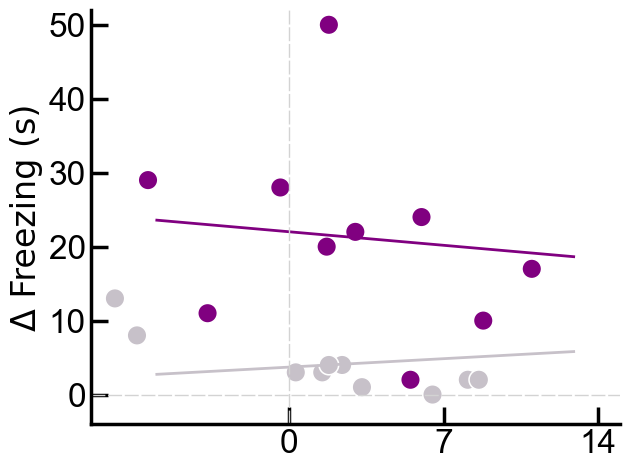

In [33]:
colors = ["purple","#c7c1c9"]

fig, ax = plt.subplots()  # create figure and axes

# plot on ax (Axes) object
# ax.plot(x, y, 'o',markersize=13,c='purple')
sns.scatterplot(data=dataframe, x='x', y='y',hue='r3r4',palette=colors,s=200)
#obtain m (slope) and b(intercept) of linear regression line
m, b = np.polyfit(x, y, 1)
m2, b2 = np.polyfit(x2,y2,1)

#add linear regression line to scatterplot 
l_reg_line = np.array([min(x.min(),x2.min()),max(x.max(),x2.max())])
ax.plot(l_reg_line, m*l_reg_line+b, color=colors[0], linewidth=2)
ax.plot(l_reg_line, m2*l_reg_line+b2, color=colors[1], linewidth=2)

#axis ticks and limits
ax.set_ylim([-4,52])
ax.set_yticks([0,10,20,30,40,50], fontname='Arial')
ax.set_yticklabels(['0','10','20','30','40','50'],fontname='Arial')

ax.set_xlim([-9,15])
ax.set_xticks([0,7,14], fontname='Arial')
ax.set_xticklabels(['0','7','14'],fontname='Arial')


#axis spines
sns.despine(top=True, right=True, left=False, bottom=False)
ax.spines['left'].set_linewidth(2.5)
ax.spines['bottom'].set_linewidth(2.5)
ax.set_xlabel('Δ Decoding accuracy', fontsize=24)
ax.set_xlabel('', fontsize=24)

ax.set_ylabel('Δ Freezing (s)', fontsize=24)

plt.axhline(y=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))
plt.axvline(x=0,linewidth=1, color='lightgrey',ls='--', dashes=(10, 2))


#ax.tick_params(axis='both', which='major', )
ax.tick_params(axis='both', which='major', direction='in',length=12, labelsize=24, width=2.5)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles,['Recall 1&2', 'Recall 3&4'], fontsize = 18, frameon=False, loc='upper left')

plt.legend().remove()

plt.tight_layout()
fig.tight_layout()
fig.savefig("SpatialDecoding_FreezCorr.jpg",dpi=500)
plt.savefig('SpatialDecoding_FreezCorr.eps', format='eps',dpi=500)


In [4]:
x_df = list(x)
x_df.extend(x2)
y_df = list(y)
y_df.extend(y2)
flag.extend(flag_2)

dataframe = pd.DataFrame(list(zip(x_df, y_df, flag)),columns=['x','y','r3r4'])